# RateBeer: Predicting a Reviewer's Overall Score
Exploratory analysis and predictive task

First explore the data to find interesting patterns, then choose a predictive task that those patterns support. 

All scores are kept on RateBeer's original scale (overall = 1 to 20), so every number and every future MSE uses the same units.

In [1]:
import ast, html, os, time, string
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

main_color, second_color, text_color = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.labelcolor": text_color,
    "xtick.color": text_color, "ytick.color": text_color,
})

## Part A. Where the data comes from

- Source: the RateBeer file from Professor Julian McAuley's dataset page at UCSD (https://cseweb.ucsd.edu/~jmcauley/datasets.html#multi_aspect), listed under "multi-aspect reviews" next to BeerAdvocate.
- What a review contains: beer name, beer ID, brewer ID, ABV, style, a date, the reviewer's profile name, the review text, and five scores: appearance (out of 5), aroma (10), palate (5), taste (10) and overall (20). Together the five add up to 50 points, which RateBeer divides by 10 to show a rating out of 5.
- Why it was collected: for research on reviews that rateseveral aspects of a product (McAuley, Leskovec & Jurafsky, "Learning attitudes and attributes from multi-aspect reviews", ICDM 2012) and on how reviewers' tastes change as they gain experience (McAuley & Leskovec, "From amateurs to connoisseurs", WWW 2013).
- Size according to the dataset page: 2,855,232 reviews, 40,213 users and 110,419 beers, April 2000 to November 2011. Our own counts are in Part C.

In [2]:
data_file = "ratebeer.json"
start_time = time.time()

column_values = {}       
shared_copy = {}         
expected_columns = None
bad_lines = 0
empty_records = 0

with open(data_file, "r", encoding="utf-8") as file:
    for line in file:
        line = line.strip()
        if line == "":
            continue
        try:
            record = ast.literal_eval(line)         
        except (ValueError, SyntaxError):
            bad_lines += 1
            continue
        if len(record) == 0:                         
            empty_records += 1
            continue
        if expected_columns is None:
            expected_columns = list(record.keys())
            for column_name in expected_columns:
                column_values[column_name] = []
        for column_name in expected_columns:
            value = record.get(column_name)
            if column_name != "review/text":
                if value not in shared_copy:
                    shared_copy[value] = value
                value = shared_copy[value]
            column_values[column_name].append(value)

df = pd.DataFrame(column_values)
del column_values, shared_copy

df = df.rename(columns={
    "beer/name": "beer_name", "beer/beerId": "beer_id", "beer/brewerId": "brewer_id",
    "beer/ABV": "abv", "beer/style": "beer_style", "review/appearance": "appearance",
    "review/aroma": "aroma", "review/palate": "palate", "review/taste": "taste",
    "review/overall": "overall", "review/time": "time", "review/profileName": "user",
    "review/text": "text",
})

print("Reviews loaded:", len(df), "| unreadable lines:", bad_lines, "| empty records skipped:", empty_records)
display(df.head(3))

Reviews loaded: 2924163 | unreadable lines: 0 | empty records skipped: 1


,beer_name,beer_id,brewer_id,abv,beer_style,appearance,aroma,palate,taste,overall,time,user,text
0,John Harvards Simcoe IPA,63836,8481,5.4,India Pale Ale &#40;IPA&#41;,4/5,6/10,3/5,6/10,13/20,1157587200,hopdog,"On tap at the Springfield, PA location. Poured..."
1,John Harvards Simcoe IPA,63836,8481,5.4,India Pale Ale &#40;IPA&#41;,4/5,6/10,4/5,7/10,13/20,1157241600,TomDecapolis,On tap at the John Harvards in Springfield PA....
2,John Harvards Cristal Pilsner,71716,8481,5,Bohemian Pilsener,4/5,5/10,3/5,6/10,14/20,958694400,PhillyBeer2112,"UPDATED: FEB 19, 2003 Springfield, PA. I've ne..."


Every line could be read. The last line of the file is an empty record `{}` (becomes a row of NaN values, so we skip it). Every field, including the numbers, arrives as text (example ABV value is `'5.4'`, example overall value is `'13/20'`).

## Part B. Cleaning the data

### B1. Missing values that pandas can't see

`isnull()` only recognizes `None` and `NaN`. A placeholder such as `'-'` or an empty string `''` is ordinary text to pandas, so it is counted as a real value. That is why the first check reports nothing missing:

In [3]:
pandas_missing_counts = df.isnull().sum()
print("Missing values reported by isnull():", pandas_missing_counts.sum())

Missing values reported by isnull(): 0


To find hidden placeholders, we scan every column for values that are empty, made only of symbols (no letter or digit, e.g. `'-'`), or common "missing" words such as `'n/a'` or `'null'`.

In [4]:
null_words = ["n/a", "na", "null", "none", "nan", "unknown", "missing"]

placeholder_rows = []
for column_name in df.columns:
    values = df[column_name].str.strip()
    is_empty = values == ""
    is_symbols_only = ~values.str.contains(r"[A-Za-z0-9]") & ~is_empty
    short_values = values[values.str.len() <= 10]
    is_null_word = short_values.str.lower().isin(null_words)

    flagged = pd.concat([values[is_empty | is_symbols_only], short_values[is_null_word]])
    examples = []
    for flagged_value, count in flagged.value_counts().head(3).items():
        examples.append(repr(flagged_value[:12]) + " x " + str(count))

    placeholder_rows.append({"column": column_name, "empty": is_empty.sum(),
                             "symbols only": is_symbols_only.sum(), "missing-words": is_null_word.sum(),
                             "examples": ", ".join(examples)})
pd.DataFrame(placeholder_rows)

,column,empty,symbols only,missing-words,examples
0,beer_name,0,0,0,
1,beer_id,0,0,0,
2,brewer_id,0,0,0,
3,abv,0,138637,0,'-' x 138637
4,beer_style,0,0,0,
5,appearance,0,0,0,
6,aroma,0,0,0,
7,palate,0,0,0,
8,taste,0,0,0,
9,overall,0,0,0,


Three columns are flagged:
- abv: 138,637 reviews use `'-'` for an unknown ABV.
- text: 5,002 reviews are empty and 86 contain only symbols. A further check below finds texts with no letters at all and two import messages that say the review has no comments.
- user: 68 reviews come from a profile literally named `'missing'`. Its reviews cover 66 beers from 2006 to 2009 in one consistent writing style. We decided to keep it. An automatic scan only points at suspicious values.

In [5]:
text_has_letters = df["text"].str.contains(r"[A-Za-z]")
system_messages = [
    "(This beer rating was imported from FB and unfortunately lacks any further comments.)",
    "Imported from Beerseek, no description given with original rating. Need to re-rate beer.",
]
is_system_message = df["text"].str.strip().isin(system_messages)
print("Texts with no letters:", (~text_has_letters).sum(), "| import messages with no review:", is_system_message.sum())
reviews_by_missing = df[df["user"] == "missing"]
missing_user_years = pd.to_datetime(pd.to_numeric(reviews_by_missing["time"]), unit="s").dt.year
print("Profile named 'missing':", len(reviews_by_missing), "reviews of", reviews_by_missing["beer_id"].nunique(),
      "different beers,", missing_user_years.min(), "to", missing_user_years.max())

df["abv"] = df["abv"].replace("-", np.nan)
df.loc[~text_has_letters | is_system_message, "text"] = np.nan

missing_after = df.isnull().sum()
missing_table = pd.DataFrame({"missing before": pandas_missing_counts, "missing after": missing_after,
                              "% of reviews": (missing_after / len(df) * 100).round(2)})
missing_table[missing_table["missing after"] > 0]

Texts with no letters: 5110 | import messages with no review: 75
Profile named 'missing': 68 reviews of 66 different beers, 2006 to 2009


,missing before,missing after,% of reviews
abv,0,138637,4.74
text,0,5185,0.18


Now, pandas sees 138,637 missing ABVs (4.74%) and 5,185 missing texts (0.18%). Before, it saw none.

### B2. Converting text to numbers and dates

In [6]:
# Scores: "13/20" -> 13 (each column has at most 20 distinct values, so we check each one)
for column_name in ["appearance", "aroma", "palate", "taste", "overall"]:
    score_of = {}
    maximums_found = []
    for value in df[column_name].unique():
        parts = value.split("/")
        score_of[value] = int(parts[0])
        if int(parts[1]) not in maximums_found:
            maximums_found.append(int(parts[1]))
    df[column_name] = df[column_name].map(score_of)
    print(column_name.ljust(10), "maximum:", maximums_found, "| range:", df[column_name].min(), "to", df[column_name].max())

# ABV: raises an error if any non-number other than the removed "-" were left
df["abv"] = pd.to_numeric(df["abv"])

# Time: seconds since 1 Jan 1970 -> date
df["time"] = pd.to_numeric(df["time"])
df["date"] = pd.to_datetime(df["time"], unit="s")
print("Dates:", df["date"].min().date(), "to", df["date"].max().date(),
      "| timestamps that are not midnight:", (df["time"] % 86400 != 0).sum())
print("ABV range:", df["abv"].min(), "to", df["abv"].max(), "| reviews above 20% ABV:", (df["abv"] > 20).sum())

appearance maximum: [5] | range: 1 to 5
aroma      maximum: [10] | range: 1 to 10
palate     maximum: [5] | range: 1 to 5
taste      maximum: [10] | range: 1 to 10
overall    maximum: [20] | range: 1 to 20
Dates: 2000-04-12 to 2012-01-13 | timestamps that are not midnight: 0
ABV range: 0.01 to 57.7 | reviews above 20% ABV: 1631


- Every score has the form `score/maximum` with one maximum per column, and no score falls outside its range.
- Every timestamp is exactly midnight, so we know the date of a review but not the time of day.
- ABV runs from 0.01% (alcohol-free beers) to 57.7% (an extreme German eisbock). These are real beers, so nothing is removed.

We wondered if a missing ABV was random, so we also compared reviews of beers with and without one.

In [7]:
abv_missing_rows = df["abv"].isnull()
comparison_rows = []
for group_name, group_mask in [("ABV known", ~abv_missing_rows), ("ABV missing", abv_missing_rows)]:
    group = df[group_mask]
    comparison_rows.append({"group": group_name, "reviews": len(group), "beers": group["beer_id"].nunique(),
                            "median reviews per beer": group["beer_id"].value_counts().median(),
                            "average overall": round(group["overall"].mean(), 2)})
pd.DataFrame(comparison_rows)

,group,reviews,beers,median reviews per beer,average overall
0,ABV known,2785526,87249,5.0,13.24
1,ABV missing,138637,23120,2.0,12.48


Beers without an ABV get far fewer reviews (median 2 vs. 5) and lower scores (12.48 vs. 13.24). They are mostly small, rarely reviewed beers, so the gap doesn't seem to be random. We keep these reviews and plan to use a "ABV missing" feature (either 0 or 1) instead of dropping them.

### B3. HTML codes and lost accents

Names and styles contain web codes such as `&#40;` for "(" (the IPA style is stored as `India Pale Ale &#40;IPA&#41;`). Accented letters were also deleted before the file was published. For example, "Kölsch" appears as `Klsch` and "Märzen" as `Mrzen`. We decode the HTML codes and restore the 16 style names whose spelling is certain. Beer names keep their missing letters, which is harmless because models will use `beer_id`.

In [8]:
html_code_pattern = r"&#?[A-Za-z0-9]+;"
print("Reviews with HTML codes -> names:", df["beer_name"].str.contains(html_code_pattern).sum(),
      "| styles:", df["beer_style"].str.contains(html_code_pattern).sum(),
      "| texts:", df["text"].str.contains(html_code_pattern, na=False).sum())
print("Values with any accented character:", df["beer_name"].str.contains(r"[^\x00-\x7F]").sum())

style_name_fixes = {"Klsch": "Kölsch", "Bire de Garde": "Bière de Garde", "Oktoberfest/Mrzen": "Oktoberfest/Märzen"}
for column_name in ["beer_name", "beer_style"]:
    cleaned_value_of = {}
    for original_value in df[column_name].unique():
        cleaned_value = html.unescape(original_value)
        if column_name == "beer_style":
            cleaned_value = style_name_fixes.get(cleaned_value, cleaned_value)
            if cleaned_value.startswith("Sak - "):
                cleaned_value = "Saké - " + cleaned_value[len("Sak - "):]
        cleaned_value_of[original_value] = cleaned_value
    df[column_name] = df[column_name].map(cleaned_value_of)

text_has_code = df["text"].str.contains(html_code_pattern, na=False)
df.loc[text_has_code, "text"] = df.loc[text_has_code, "text"].apply(html.unescape)
print("Example style after cleaning:", df.loc[0, "beer_style"])

Reviews with HTML codes -> names: 214417 | styles: 234046 | texts: 4547
Values with any accented character: 0
Example style after cleaning: India Pale Ale (IPA)


### B4. Duplicate reviews

In [9]:
print("Exact duplicate rows:", df.duplicated().sum())
repeated_pair = df.duplicated(subset=["user", "beer_id"], keep=False)
print("Extra copies of a (user, beer) pair:", df.duplicated(subset=["user", "beer_id"]).sum())

# What differs between the two copies?
repeated_rows = df[repeated_pair]
for column_name in ["brewer_id", "overall", "text", "date"]:
    pairs_that_differ = (repeated_rows.groupby(["user", "beer_id"])[column_name].nunique(dropna=False) > 1).sum()
    print("   pairs whose copies differ in", column_name.ljust(9), ":", pairs_that_differ)

df = df.drop_duplicates(subset=["user", "beer_id"], keep="first").reset_index(drop=True)
print("Reviews after removing copies:", len(df))

Exact duplicate rows: 4
Extra copies of a (user, beer) pair: 68931
   pairs whose copies differ in brewer_id : 68926
   pairs whose copies differ in overall   : 1
   pairs whose copies differ in text      : 2
   pairs whose copies differ in date      : 0
Reviews after removing copies: 2855232


Only 4 rows are exact copies, but 68,931 reviews appear twice, almost always identical except for the brewer ID. The beer is listed under two brewers (for example, a contract-brewed beer), and each review was collected once from each brewer's page. If one copy landed in the training set and the other in the test set, the model would be tested on a review it had already seen. Therefore, we keep the first copy.

After this step, we have 2,855,232 reviews, which is exactly the number on the dataset page. This confirms the duplicates were collection artifacts.

### B5. Cleaning summary

| Issue | What we did | Reviews affected |
|---|---|---|
| Empty record at the end of the file | Skipped while loading | 1 |
| ABV written as `'-'` | Set to NaN, rows kept, "ABV missing" feature planned | 138,637 |
| Empty or meaningless review text | Set to NaN | 5,185 |
| Numbers stored as text | Checked format and range, converted to numbers and dates | all |
| HTML codes, lost accents | Decoded codes, fixed 16 style names | ~450,000 |
| Same review collected twice | Kept the first copy | 68,931 removed |

## Part C. Basic statistics

In [10]:
reviews_per_user = df["user"].value_counts()
reviews_per_beer = df["beer_id"].value_counts()
df["word_count"] = df["text"].str.count(r"\S+")
density = len(df) / (df["user"].nunique() * df["beer_id"].nunique()) * 100
non_beer_styles = ["Cider", "Perry", "Ice Cider/Perry", "Mead"] + [style for style in df["beer_style"].unique() if style.startswith("Saké")]
print(f"Reviews of drinks that aren't beer (cider, perry, mead, saké): {df['beer_style'].isin(non_beer_styles).mean() * 100:.2f}%")

pd.DataFrame({"value": [
    f"{len(df):,}", f"{df['user'].nunique():,}", f"{df['beer_id'].nunique():,}", f"{df['brewer_id'].nunique():,}",
    f"{df['beer_style'].nunique()}", f"{df['date'].min().date()} to {df['date'].max().date()}",
    f"{df['word_count'].median():.0f}", f"{density:.3f}%",
]}, index=["reviews", "users (profile names)", "beers", "brewers", "styles", "dates",
           "median words per review", "density: reviews / (users x beers)"])

Reviews of drinks that aren't beer (cider, perry, mead, saké): 1.25%


,value
reviews,"2,855,232"
users (profile names),"29,265"
beers,"110,369"
brewers,"7,424"
styles,89
dates,2000-04-12 to 2012-01-13
median words per review,44
density: reviews / (users x beers),0.088%


- We have fewer users than the dataset page (29,265 vs. 40,213) because the file only has profile names and not user IDs.
- Only 0.088% of all possible (user, beer) pairs have a review, so the user–beer rating matrix is extremely sparse.
- About 1.25% of reviews are of drinks that aren't beer (cider, perry, mead, saké). They use the same scale, so we keep them.

The target we're choosing is the overall score.

mean 13.24 | median 14 | standard deviation 3.33 | variance 11.07 | skew -1.03
share of scores from 12 to 17: 71.0%


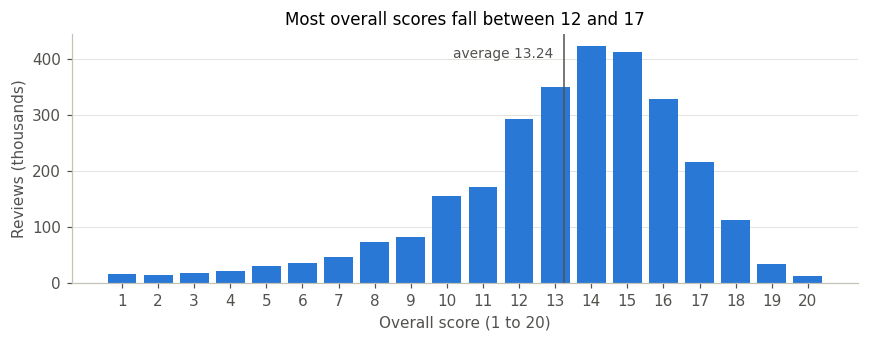

In [11]:
overall_counts = df["overall"].value_counts().sort_index()
overall_mean = df["overall"].mean()
overall_variance = ((df["overall"] - overall_mean) ** 2).mean()
print(f"mean {overall_mean:.2f} | median {df['overall'].median():.0f} | standard deviation {overall_variance ** 0.5:.2f}"
      f" | variance {overall_variance:.2f} | skew {df['overall'].skew():.2f}")
print(f"share of scores from 12 to 17: {df['overall'].between(12, 17).mean() * 100:.1f}%")

figure, axis = plt.subplots(figsize=(8, 3.2))
axis.bar(overall_counts.index, overall_counts.values / 1000, color=main_color, width=0.8)
axis.axvline(overall_mean, color=text_color, linewidth=1)
axis.text(overall_mean - 0.3, overall_counts.max() / 1000 * 0.95, f"average {overall_mean:.2f}", ha="right", color=text_color, fontsize=9)
axis.set_xticks(range(1, 21))
axis.set_xlabel("Overall score (1 to 20)")
axis.set_ylabel("Reviews (thousands)")
axis.set_title("Most overall scores fall between 12 and 17")
axis.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

The average overall score is 13.24, and 71% of scores fall between 12 and 17. The distribution leans left (skew −1.03): low scores trail off in a long tail while top scores are rare. Always predicting the average gives an MSE equal to the variance (11.07), which is the bar every model must clear.

## Part D. Patterns in the data

### D1. A few users and beers account for most reviews

users: % of users per bucket {'1': 32.8, '2-5': 27.5, '6-10': 9.5, '11-50': 14.0, '51-100': 3.9, '101-500': 7.7, '501-1000': 2.1, 'over 1000': 2.5}
users: % of all reviews per bucket {'1': 0.3, '2-5': 0.8, '6-10': 0.8, '11-50': 3.2, '51-100': 2.9, '101-500': 18.0, '501-1000': 15.0, 'over 1000': 59.0}
beers: % of beers per bucket {'1': 22.5, '2-5': 34.0, '6-10': 14.5, '11-50': 20.9, '51-100': 3.7, '101-500': 3.7, '501-1000': 0.6, 'over 1000': 0.3}
beers: % of all reviews per bucket {'1': 0.9, '2-5': 4.1, '6-10': 4.3, '11-50': 17.9, '51-100': 10.1, '101-500': 30.3, '501-1000': 15.8, 'over 1000': 16.7}


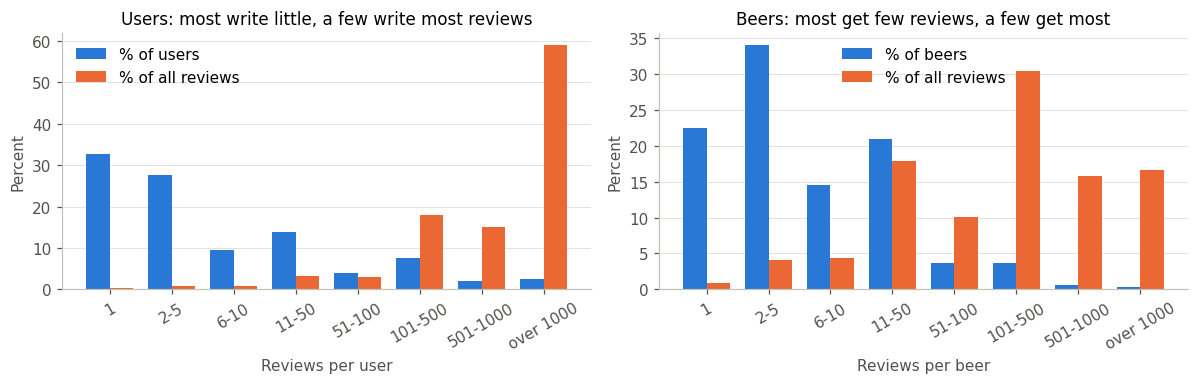

In [12]:
bucket_edges = [0, 1, 5, 10, 50, 100, 500, 1000, 100000]
bucket_labels = ["1", "2-5", "6-10", "11-50", "51-100", "101-500", "501-1000", "over 1000"]

figure, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bar_positions = np.arange(len(bucket_labels))
for axis, counts, group_label in [(axes[0], reviews_per_user, "users"), (axes[1], reviews_per_beer, "beers")]:
    bucket = pd.cut(counts, bins=bucket_edges, labels=bucket_labels)
    share_of_group = bucket.value_counts(normalize=True).sort_index() * 100
    share_of_reviews = counts.groupby(bucket, observed=False).sum() / len(df) * 100
    print(f"{group_label}: % of {group_label} per bucket", share_of_group.round(1).to_dict())
    print(f"{group_label}: % of all reviews per bucket", share_of_reviews.round(1).to_dict())
    axis.bar(bar_positions - 0.19, share_of_group.values, width=0.38, color=main_color, label="% of " + group_label)
    axis.bar(bar_positions + 0.19, share_of_reviews.values, width=0.38, color=second_color, label="% of all reviews")
    axis.set_xticks(bar_positions)
    axis.set_xticklabels(bucket_labels, rotation=30)
    axis.set_xlabel("Reviews per " + group_label[:-1])
    axis.set_ylabel("Percent")
    axis.grid(axis="x", visible=False)
    axis.legend(frameon=False)
axes[0].set_title("Users: most write little, a few write most reviews")
axes[1].set_title("Beers: most get few reviews, a few get most")
plt.tight_layout()
plt.show()

A third of users wrote one review, yet the 4.6% who wrote more than 500 reviews produced 74% of all reviews. Likewise, 4.6% of beers (those with over 100 reviews) received 63% of the reviews. An MSE over all reviews is therefore driven mostly by heavy users and popular beers, so we will also report errors for rarely seen users and beers (the cold-start case).

### D2. Scores change over time

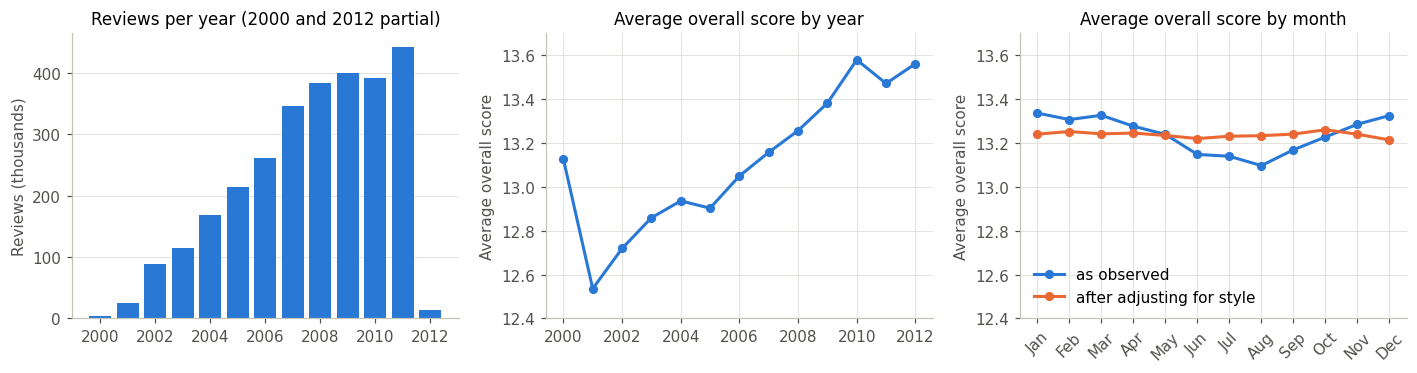

Average by month: {1: 13.34, 2: 13.31, 3: 13.33, 4: 13.28, 5: 13.24, 6: 13.15, 7: 13.14, 8: 13.1, 9: 13.17, 10: 13.23, 11: 13.28, 12: 13.32}
Monthly swing as observed: 0.24 | after adjusting for style: 0.05
Imperial Stout: 5.0% of January reviews vs 3.5% of August reviews
Pale Lager: 4.8% of January reviews vs 5.1% of August reviews


In [13]:
review_year = df["date"].dt.year
review_month = df["date"].dt.month
reviews_per_year = df.groupby(review_year)["overall"].count()
average_by_year = df.groupby(review_year)["overall"].mean()
average_by_month = df.groupby(review_month)["overall"].mean()

# Remove the effect of which styles people review in each month: score minus the style's average
style_average = df.groupby("beer_style")["overall"].transform("mean")
style_adjusted_by_month = (df["overall"] - style_average).groupby(review_month).mean() + overall_mean

figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].bar(reviews_per_year.index, reviews_per_year.values / 1000, color=main_color)
axes[0].set_title("Reviews per year (2000 and 2012 partial)")
axes[0].set_ylabel("Reviews (thousands)")
axes[0].grid(axis="x", visible=False)
axes[1].plot(average_by_year.index, average_by_year.values, color=main_color, linewidth=2, marker="o", markersize=5)
axes[1].set_title("Average overall score by year")
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
axes[2].plot(range(1, 13), average_by_month.values, color=main_color, linewidth=2, marker="o", markersize=5, label="as observed")
axes[2].plot(range(1, 13), style_adjusted_by_month.values, color=second_color, linewidth=2, marker="o", markersize=5, label="after adjusting for style")
axes[2].set_xticks(range(1, 13))
axes[2].set_xticklabels(month_names, rotation=45)
axes[2].set_title("Average overall score by month")
axes[2].legend(frameon=False, loc="lower left")
for axis in axes[:2]:
    axis.set_xticks(range(2000, 2013, 2))
for axis in axes[1:]:
    axis.set_ylim(12.4, 13.7)
    axis.set_ylabel("Average overall score")
plt.tight_layout()
plt.show()

print("Average by month:", average_by_month.round(2).to_dict())
print(f"Monthly swing as observed: {average_by_month.max() - average_by_month.min():.2f} | "
      f"after adjusting for style: {style_adjusted_by_month.max() - style_adjusted_by_month.min():.2f}")
for style_name in ["Imperial Stout", "Pale Lager"]:
    share_by_month = (df["beer_style"] == style_name).groupby(review_month).mean() * 100
    print(f"{style_name}: {share_by_month[1]:.1f}% of January reviews vs {share_by_month[8]:.1f}% of August reviews")

- Year: activity grows to about 400,000 reviews a year by 2009–2011, and the average score climbs from about 12.5 (2001) to about 13.5 (2010–2012). A year feature or a time-dependent bias can capture this.
- Month: scores are lowest in August (13.10) and highest in January (13.34). The orange line shows that this is mostly a style effect. People review more imperial stouts in winter and fewer in summer, and stouts score high. After subtracting each style's average, the monthly swing shrinks from 0.24 to about 0.05 points. So style matters much more than the calendar month.
- Both line charts share one y-axis, so the yearly drift (about 1 point) can be compared directly with the monthly swing.

### D3. How the overall score relates to the other columns

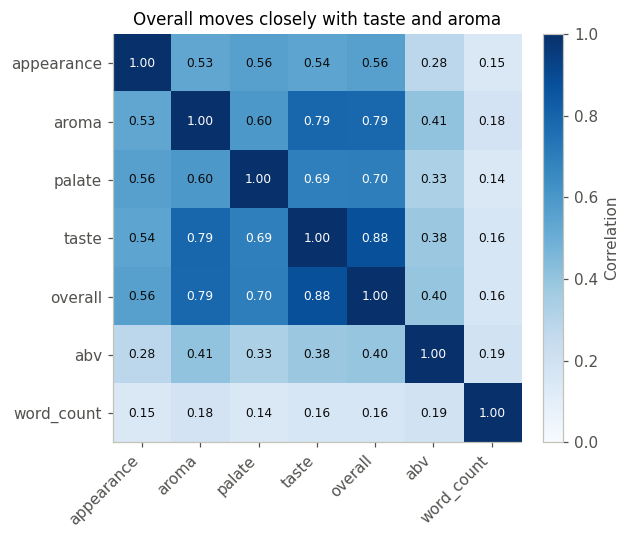

In [14]:
correlation_columns = ["appearance", "aroma", "palate", "taste", "overall", "abv", "word_count"]
correlation_matrix = df[correlation_columns].corr()

figure, axis = plt.subplots(figsize=(6.2, 5))
image = axis.imshow(correlation_matrix.values, cmap="Blues", vmin=0, vmax=1)
axis.set_xticks(range(len(correlation_columns)))
axis.set_yticks(range(len(correlation_columns)))
axis.set_xticklabels(correlation_columns, rotation=45, ha="right")
axis.set_yticklabels(correlation_columns)
axis.grid(False)
for row_number in range(len(correlation_columns)):
    for column_number in range(len(correlation_columns)):
        value = correlation_matrix.values[row_number, column_number]
        axis.text(column_number, row_number, f"{value:.2f}", ha="center", va="center", fontsize=8,
                  color="white" if value > 0.6 else "#0b0b0b")
figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04, label="Correlation")
axis.set_title("Overall moves closely with taste and aroma")
plt.tight_layout()
plt.show()

The four other scores are almost the same opinion as the overall score (taste 0.88, aroma 0.79, palate 0.70, appearance 0.57). They are entered at the same moment, so a model that uses them would mostly learn how people combine their own sub-scores, and it couldn't predict a score for a beer the user hasn't reviewed yet. ABV (0.40) and review length (0.16) are weaker but real signals.

### D4. Beer style and strength

Most reviewed styles: India Pale Ale (IPA), Pale Lager, Belgian Strong Ale, Imperial Stout, Imperial/Double IPA
Lowest: {'Low Alcohol': 6.33, 'Malt Liquor': 6.81, 'Pale Lager': 7.49}
Highest: {'Abt/Quadrupel': 15.68, 'Ice Cider/Perry': 15.81, 'Imperial Stout': 15.87}


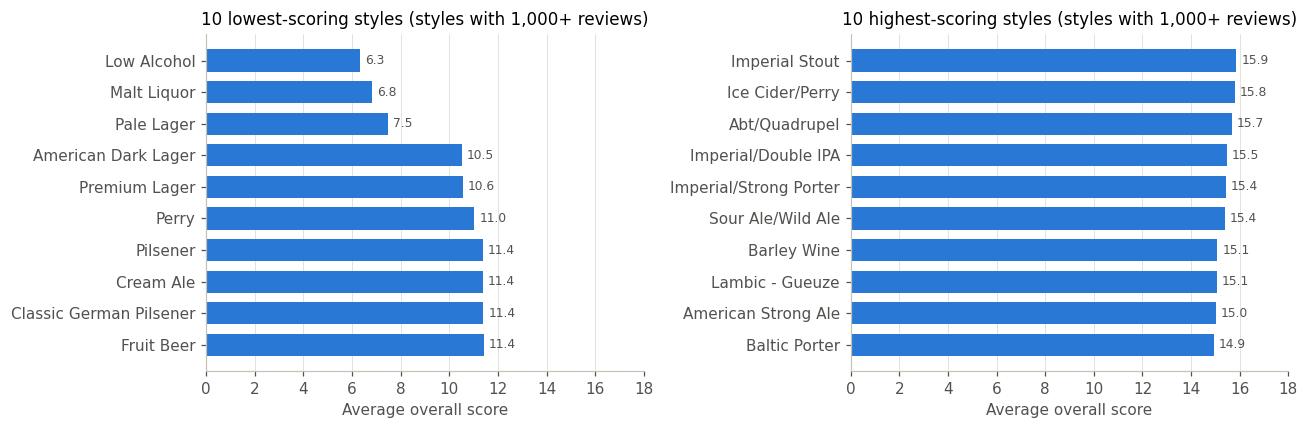

In [15]:
style_summary = df.groupby("beer_style")["overall"].agg(["mean", "count"])
common_styles = style_summary[style_summary["count"] >= 1000].sort_values("mean")
print("Most reviewed styles:", ", ".join(style_summary.sort_values("count", ascending=False).index[:5]))
print("Lowest:", common_styles["mean"].head(3).round(2).to_dict())
print("Highest:", common_styles["mean"].tail(3).round(2).to_dict())

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, styles_to_plot, panel_title in [(axes[0], common_styles.head(10).iloc[::-1], "10 lowest-scoring styles"),
                                          (axes[1], common_styles.tail(10), "10 highest-scoring styles")]:
    axis.barh(styles_to_plot.index, styles_to_plot["mean"], color=main_color, height=0.7)
    for row_number, average_score in enumerate(styles_to_plot["mean"]):
        axis.text(average_score + 0.2, row_number, f"{average_score:.1f}", va="center", fontsize=8, color=text_color)
    axis.set_xlim(0, 18)
    axis.set_xlabel("Average overall score")
    axis.set_title(panel_title + " (styles with 1,000+ reviews)")
    axis.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Average overall by ABV range: {'0-3': 7.33, '3-4': 11.28, '4-5': 11.48, '5-6': 12.94, '6-7': 14.09, '7-8': 14.38, '8-9': 14.7, '9-10': 15.24, '10-12': 15.47, '12-15': 15.48, '15+': 15.08}


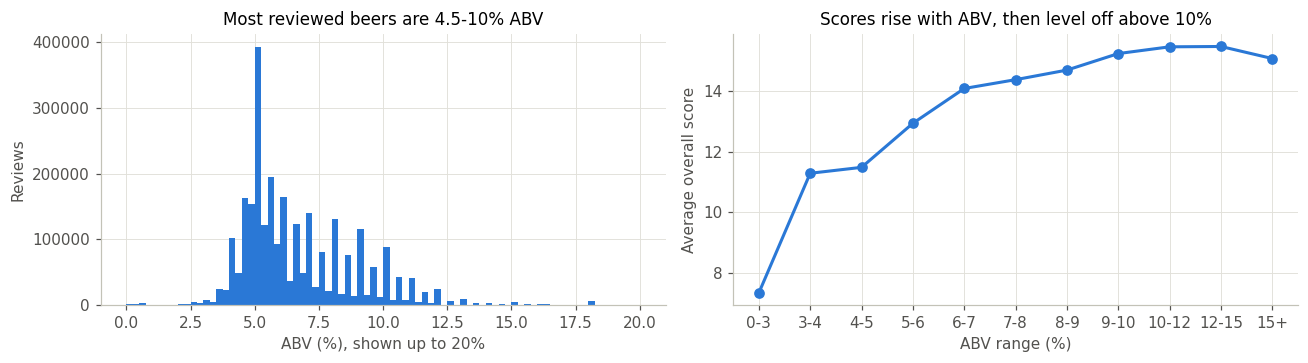

In [16]:
abv_edges = [0, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 60]
abv_labels = ["0-3", "3-4", "4-5", "5-6", "6-7", "7-8", "8-9", "9-10", "10-12", "12-15", "15+"]
average_by_abv = df.groupby(pd.cut(df["abv"], bins=abv_edges, labels=abv_labels), observed=False)["overall"].mean()
print("Average overall by ABV range:", average_by_abv.round(2).to_dict())

figure, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(df["abv"].dropna(), bins=np.arange(0, 20.25, 0.25), color=main_color)
axes[0].set_xlabel("ABV (%), shown up to 20%")
axes[0].set_ylabel("Reviews")
axes[0].set_title("Most reviewed beers are 4.5-10% ABV")
axes[1].plot(abv_labels, average_by_abv.values, color=main_color, linewidth=2, marker="o", markersize=6)
axes[1].set_xlabel("ABV range (%)")
axes[1].set_ylabel("Average overall score")
axes[1].set_title("Scores rise with ABV, then level off above 10%")
plt.tight_layout()
plt.show()

- Style: averages run from about 6 (low-alcohol beer, malt liquor) to almost 16 (imperial stout, quadrupel, double IPA). Style is a strong candidate feature (one-hot encoded). IPA is the most reviewed style.
- ABV: most reviews are of 4.5–10% beers. The average score climbs from 7.3 below 3% to about 15.5 at 10–15%, then dips slightly. A curve like this needs more than one straight-line term, for example ABV plus ABV², as in the course's beer regression example. Style and ABV overlap, because strong styles are high in alcohol.

### D5. Review text

Average overall by review length: {'1-20': 11.99, '21-40': 12.79, '41-60': 13.44, '61-80': 13.76, '81-100': 14.0, '101-150': 14.21, '151-200': 14.5, '200+': 14.84}


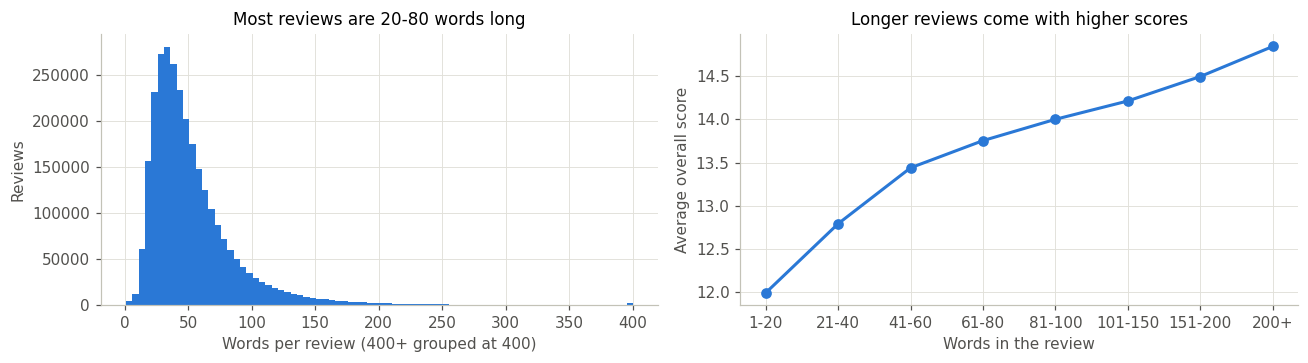

In [17]:
length_edges = [0, 20, 40, 60, 80, 100, 150, 200, 5000]
length_labels = ["1-20", "21-40", "41-60", "61-80", "81-100", "101-150", "151-200", "200+"]
average_by_length = df.groupby(pd.cut(df["word_count"], bins=length_edges, labels=length_labels), observed=False)["overall"].mean()
print("Average overall by review length:", average_by_length.round(2).to_dict())

figure, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(df["word_count"].dropna().clip(upper=400), bins=80, color=main_color)
axes[0].set_xlabel("Words per review (400+ grouped at 400)")
axes[0].set_ylabel("Reviews")
axes[0].set_title("Most reviews are 20-80 words long")
axes[1].plot(length_labels, average_by_length.values, color=main_color, linewidth=2, marker="o", markersize=6)
axes[1].set_xlabel("Words in the review")
axes[1].set_ylabel("Average overall score")
axes[1].set_title("Longer reviews come with higher scores")
plt.tight_layout()
plt.show()

Another question we wanted to answer was: Which words separate low scores (8 or less) from high scores (17 or more)?

We used a sample of 50,000 reviews to investigate this. 

In [18]:
sampled_reviews = df.loc[df["text"].notnull(), ["text", "overall"]].sample(n=50000, random_state=42)
punctuation = set(string.punctuation)
low_word_counts, high_word_counts = defaultdict(int), defaultdict(int)
total_low_words, total_high_words = 0, 0

for review_text, overall_score in zip(sampled_reviews["text"], sampled_reviews["overall"]):
    if 8 < overall_score < 17:
        continue
    words = "".join([character for character in review_text.lower() if character not in punctuation]).split()
    for word in words:
        if overall_score <= 8:
            low_word_counts[word] += 1
        else:
            high_word_counts[word] += 1
    if overall_score <= 8:
        total_low_words += len(words)
    else:
        total_high_words += len(words)

word_rows = []
for word in set(low_word_counts) | set(high_word_counts):
    if low_word_counts[word] + high_word_counts[word] < 50:
        continue
    low_rate = low_word_counts[word] / total_low_words * 10000      # uses per 10,000 words
    high_rate = high_word_counts[word] / total_high_words * 10000
    word_rows.append({"word": word, "low": (low_rate + 1) / (high_rate + 1), "high": (high_rate + 1) / (low_rate + 1)})
word_table = pd.DataFrame(word_rows)
low_words = word_table.sort_values("low", ascending=False).head(12)
high_words = word_table.sort_values("high", ascending=False).head(12)
pd.DataFrame({"low-score word": low_words["word"].values, "x more common in low reviews": low_words["low"].round(1).values,
              "high-score word": high_words["word"].values, "x more common in high reviews": high_words["high"].round(1).values},
             index=range(1, 13))

,low-score word,x more common in low reviews,high-score word,x more common in high reviews
1,corn,18.6,bourbon,12.6
2,watery,15.8,rich,10.2
3,boring,8.6,complex,8.6
4,bland,8.5,excellent,8.2
5,water,7.8,oak,7.7
6,weak,7.6,delicious,7.3
7,cheap,7.6,chocolate,7.3
8,bad,7.4,coffee,6.7
9,skunky,7.2,balanced,6.3
10,lager,6.9,pine,6.2


Review length and score rise together (about 12.0 for very short reviews, 14.8 for reviews over 200 words). Low scores bring words like *corn, watery, bland, skunky, cheap*; high scores bring *bourbon, rich, complex, oak, delicious*. The text clearly carries information about the score, so a bag-of-words model is a sensible comparison setting.

### D6. Some users are more generous, and some beers are better liked

users with 10+ reviews: 9,233, spread of their averages (st. dev.) 1.98
   middle half of users average between 12.4 and 14.8
beers with 10+ reviews: 34,477, spread of their averages (st. dev.) 2.30


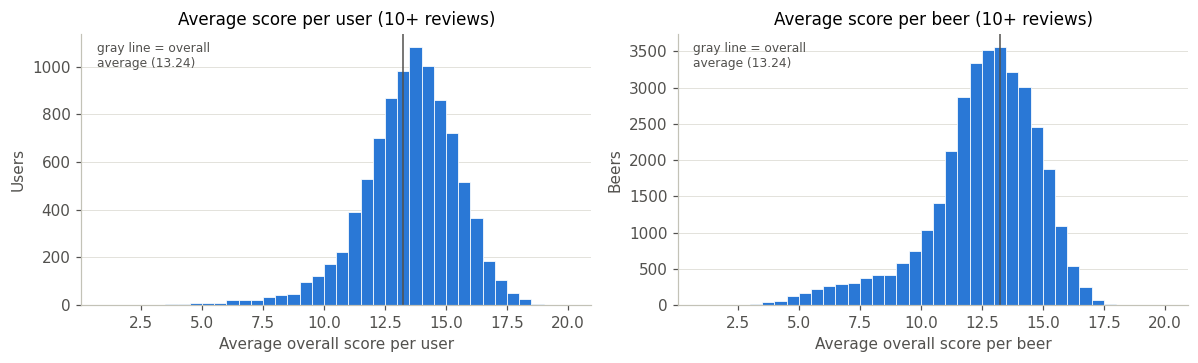

In [19]:
user_summary = df.groupby("user")["overall"].agg(["mean", "count"])
beer_summary = df.groupby("beer_id")["overall"].agg(["mean", "count"])
active_users = user_summary[user_summary["count"] >= 10]["mean"]
reviewed_beers = beer_summary[beer_summary["count"] >= 10]["mean"]
print(f"users with 10+ reviews: {len(active_users):,}, spread of their averages (st. dev.) {active_users.std():.2f}")
print(f"   middle half of users average between {active_users.quantile(0.25):.1f} and {active_users.quantile(0.75):.1f}")
print(f"beers with 10+ reviews: {len(reviewed_beers):,}, spread of their averages (st. dev.) {reviewed_beers.std():.2f}")

figure, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for axis, averages, label in [(axes[0], active_users, "user"), (axes[1], reviewed_beers, "beer")]:
    axis.hist(averages, bins=np.arange(1, 20.5, 0.5), color=main_color, edgecolor="white", linewidth=0.5)
    axis.axvline(overall_mean, color=text_color, linewidth=1)
    axis.text(0.03, 0.88, f"gray line = overall\naverage ({overall_mean:.2f})", transform=axis.transAxes, color=text_color, fontsize=8)
    axis.set_xlabel(f"Average overall score per {label}")
    axis.set_ylabel(label.capitalize() + "s")
    axis.set_title(f"Average score per {label} (10+ reviews)")
    axis.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Users differ in how generous they are (the middle half average between 12.4 and 14.8), and beers differ even more (spread 2.30 vs. 1.98). This is exactly what a bias-only model captures: one offset per user and one per beer.

### D7. Experience and reviewing many beers in one day

By review number: {'1': 14.45, '2-5': 13.76, '6-10': 13.42, '11-25': 13.33, '26-50': 13.22, '51-100': 13.24, '101-250': 13.34, '251-500': 13.33, '501-1000': 13.3, '1001-2500': 13.17, '2500+': 12.79}
Compared with own average (users with 50+ reviews): {'1': 0.59, '2-5': 0.19, '6-10': 0.01, '11-25': -0.14, '26-50': -0.2, '51-100': -0.15, '101-250': -0.05, '251-500': -0.02, '501-1000': 0.01, '1001-2500': 0.05, '2500+': 0.15}
By reviews on the same day: {'1': 13.72, '2': 13.47, '3': 13.33, '4-5': 13.26, '6-10': 13.11, '11-20': 12.96, '21-50': 12.77, '50+': 12.6}


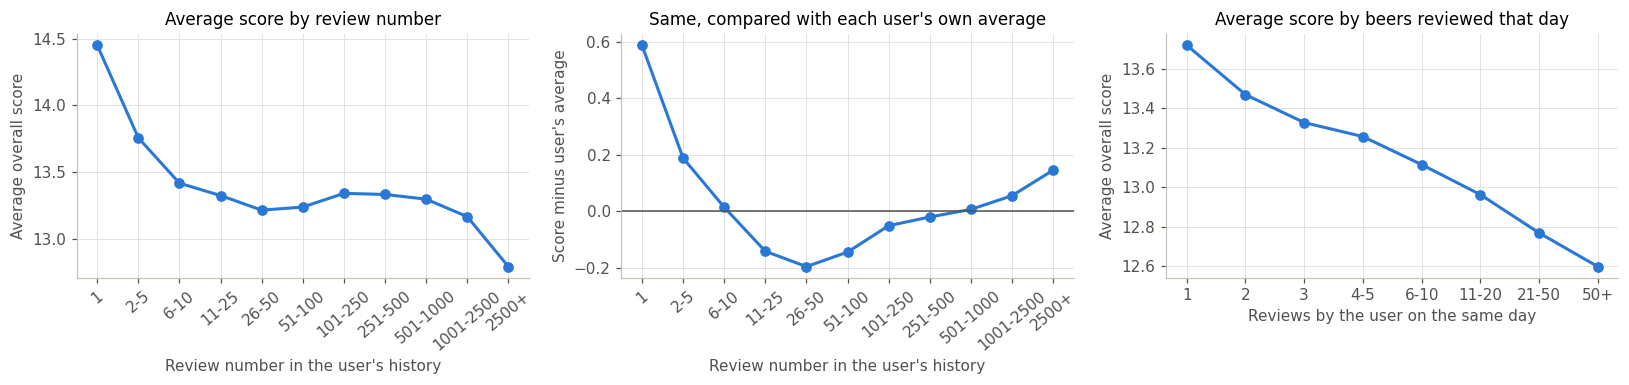

In [20]:
user_history = df[["user", "date", "overall"]].sort_values(["user", "date"], kind="stable")
df["review_number"] = user_history.groupby("user").cumcount() + 1                                 # 1st, 2nd, 3rd review ...
df["reviews_same_day"] = user_history.groupby(["user", "date"])["overall"].transform("size")       # reviews that user wrote that day

experience_edges = [0, 1, 5, 10, 25, 50, 100, 250, 500, 1000, 2500, 100000]
experience_labels = ["1", "2-5", "6-10", "11-25", "26-50", "51-100", "101-250", "251-500", "501-1000", "1001-2500", "2500+"]
experience_range = pd.cut(df["review_number"], bins=experience_edges, labels=experience_labels)
same_day_edges = [0, 1, 2, 3, 5, 10, 20, 50, 100000]
same_day_labels = ["1", "2", "3", "4-5", "6-10", "11-20", "21-50", "50+"]

# Within-user check: score minus the same user's own average (users with 50+ reviews)
difference_from_own_average = df["overall"] - df.groupby("user")["overall"].transform("mean")
heavy_user_rows = df.groupby("user")["overall"].transform("count") >= 50

average_by_experience = df.groupby(experience_range, observed=False)["overall"].mean()
within_user_by_experience = difference_from_own_average[heavy_user_rows].groupby(experience_range[heavy_user_rows], observed=False).mean()
average_by_same_day = df.groupby(pd.cut(df["reviews_same_day"], bins=same_day_edges, labels=same_day_labels), observed=False)["overall"].mean()
print("By review number:", average_by_experience.round(2).to_dict())
print("Compared with own average (users with 50+ reviews):", within_user_by_experience.round(2).to_dict())
print("By reviews on the same day:", average_by_same_day.round(2).to_dict())

figure, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(experience_labels, average_by_experience.values,
             color=main_color, linewidth=2, marker="o", markersize=6)
axes[0].set_title("Average score by review number")
axes[0].set_ylabel("Average overall score")
axes[1].plot(experience_labels, within_user_by_experience.values,
             color=main_color, linewidth=2, marker="o", markersize=6)
axes[1].axhline(0, color=text_color, linewidth=1)
axes[1].set_title("Same, compared with each user's own average")
axes[1].set_ylabel("Score minus user's average")
for axis in axes[:2]:
    axis.set_xticks(range(len(experience_labels)))
    axis.set_xticklabels(experience_labels, rotation=40)
    axis.set_xlabel("Review number in the user's history")
axes[2].plot(same_day_labels, average_by_same_day.values,
             color=main_color, linewidth=2, marker="o", markersize=6)
axes[2].set_title("Average score by beers reviewed that day")
axes[2].set_xlabel("Reviews by the user on the same day")
axes[2].set_ylabel("Average overall score")
plt.tight_layout()
plt.show()

- Experience: a user's first review averages 14.45. Compared with the user's own average (middle chart), first reviews are about 0.6 points more generous and reviews 11–100 slightly harsher, so people really do become stricter as they gain experience. The drop past review 2,500 in the left chart mostly reflects heavy users being stricter people overall.
- Same-day reviewing: users who reviewed one beer that day average 13.72, while those who reviewed more than 50 (likely at tasting events) average 12.60. Since only dates are known, this count includes reviews written later the same day, which we should mention if we use it.

### What the exploration tells us

| Finding | Evidence | Feature it suggests |
|---|---|---|
| Users differ in generosity | User averages spread by about 2 points | User bias (and a latent user vector) |
| Beers differ even more | Beer averages spread by 2.3 points | Beer bias (and a latent beer vector) |
| Style matters a lot | Averages from about 6 to 16 | One-hot style |
| ABV matters, with a curve | 7.3 below 3% up to about 15.5 at 10–15% | ABV, ABV², "ABV missing" flag |
| Scores drift upward over time | About 12.5 in 2001 to 13.5 in 2010 | Year or time-dependent bias |
| Month effect is mostly style mix | Swing drops from 0.24 to 0.05 after adjusting for style | Month adds little once style is in |
| Reviewers get stricter early on | First review +0.6 vs. own average | log(review number) |
| Many reviews in a day, lower scores | 13.72 for one beer vs. 12.60 for 50+ | log(same-day count), with a caveat |
| Text separates low and high scores | Clear word lists; longer = higher | Bag of words plus length (comparison setting) |
| Sub-scores mirror overall | Correlations 0.57–0.88 | Left out of the main model (they'd leak the answer) |

## Part E. The predictive task

Task: Predict the overall score (1–20) a reviewer will give a beer, using only information available before the review is written: who the reviewer is, which beer it is (brewer, style, ABV), and when the review happens (date and the reviewer's history so far). Part D shows that each of these carries signal.

Not used as inputs: The appearance, aroma, palate and taste scores. Reviewers enter them at the same time as the overall score, and they track it closely (correlations from 0.57 to 0.88). Using them would make the task trivial, and the model could not recommend a beer the person hasn't tried yet.

Comparing features: Starting from the bias-only model, we add beer features (style, ABV) and then time features (such as the year and how many reviews the user has already written), one group at a time, to see which ones lower the error.

How we will evaluate it:
- Mean squared error (MSE) on a held-out test set, on the original 1–20 scale. MSE is the course's standard measure for rating prediction, and it penalizes large misses more than small ones.
- Fraction of variance unexplained (FVU = MSE ÷ variance of the scores): 0 means perfect predictions, and 1 means no better than always predicting the average. It makes the models easy to compare.
- Data split: shuffle the cleaned reviews with seed 42, then use 80% for training, 10% for validation (to choose settings such as the regularization strength) and 10% for testing (used once, at the end).

Baselines to compare against:
1. Always predict the training average. Its MSE is about equal to the variance of the scores, 11.07.
2. Predict the beer's average score from the training set, and separately the user's average score. Beers or users not seen in training get the overall average.
3. Bias-only model: a global offset plus one offset per user and one per beer.

How we will check that the results are valid:
- Duplicate reviews were removed before splitting, so no review can appear in both the training and test sets.
- Every model is scored on the same test set, and nothing is tuned on it.
- We repeat the split with three different seeds and count an improvement as real only if it is larger than the change in MSE from one seed to another.
- We report the MSE separately for users and beers with fewer than 10 training reviews and for those with 10 or more. Heavy users dominate the overall MSE, and new users and beers are the hardest to predict.

In [21]:
print("Cleaned data ready for modeling:", df.shape[0], "reviews,", df.shape[1], "columns")
print(list(df.columns))

Cleaned data ready for modeling: 2855232 reviews, 17 columns
['beer_name', 'beer_id', 'brewer_id', 'abv', 'beer_style', 'appearance', 'aroma', 'palate', 'taste', 'overall', 'time', 'user', 'text', 'date', 'word_count', 'review_number', 'reviews_same_day']
